In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))   # repository root, so that `import src` works
import json
import warnings
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import cohen_kappa_score, confusion_matrix, roc_curve

from src.mass_detect.scripts.cohort import rounded_rating, suspicious
from src.mass_detect.scripts.config import CENTRE_INDEX, LIDC_MANIFEST_FILE, LNDB_MANIFEST_FILE, MODEL_RESULTS_DIR, PATCHES_DIR, ROI_DIR
from src.mass_detect.scripts.modelling import edge_share, flat, make_model
from src.mass_detect.scripts.run_models import load_tables, run as run_models

pd.set_option("display.width", 160)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h1 style="color: #c25719; border-bottom: 2px solid #c25719; padding-bottom: 8px; margin-top: 0;">
    Models and Validation
  </h1>
  <p>
  This notebook learns the malignancy rating from the features of notebook 05 and measures how well it does on both datasets, on two scales: the 1 to 5 rating, and a binary answer, suspicious (rating 4 or 5) or not. The label is the median rating of the radiologists of each nodule, rounded half up (notebook 03). Every choice is made with the same nested cross validation and the same rule fixed in advance, in five stages: the features, the way of using LNDb and LIDC IDRI together, the model, the binary answer and three extensions of the chosen model. The chosen configuration is then confirmed on new splits, tested as if it moved to a new hospital, interpreted, and finally trained on the mean and on the mode of the ratings to see what the choice of the median changes.
  </p>
  <p>
  The functions live in <strong>src/mass_detect/scripts/modelling.py</strong> (models, pooling, nested cross validation, binary answer, validation across datasets, bootstrap) and <strong>run_models.py</strong> (the stages). The comparisons take a few hours, so they run from the terminal and save their results, which this notebook reads.
  </p>
</div>

In [2]:
# Unit tests of the labels (test_labels.py), of the ordinal model (test_models.py), and of the ordinal wrapper, the binary
# answer, the pooling, the nested cross validation and the validation across datasets (test_modelling.py)
from src.mass_detect.tests import test_labels, test_modelling, test_models

tests = [getattr(test_labels, name) for name in dir(test_labels) if name.startswith("test_")]
tests += [test_models.test_probabilities_are_valid, test_models.test_recovers_the_true_weights_and_cut_points,
          test_models.test_cut_points_stay_in_order]
tests += [getattr(test_modelling, name) for name in dir(test_modelling) if name.startswith("test_")]
for test in tests:
    test()
print(f"{len(tests)} tests passed")

27 tests passed


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   The data
  </h3>
  <p>
  One row per nodule of the cohort (notebook 03) with the features kept in notebook 05 (with and without the wavelet images), its diameter, its label on both scales, its patient and dataset, and one row per reading with the rating of each radiologist.
  </p>
</div>

In [3]:
nodules, readings, feature_sets = load_tables()
print(f"{len(nodules)} nodules from {nodules['patient_id'].nunique()} patients, {len(readings)} readings")
print("features:", {name: len(features) for name, features in feature_sets.items()})

# Nodules of each rating and suspicious nodules, per dataset
counts = nodules.groupby("dataset")["rating"].value_counts().unstack()
counts["suspicious"] = nodules.groupby("dataset")["suspicious"].sum()
counts

3237 nodules from 1062 patients, 7585 readings
features: {'with_wavelet': 169, 'without_wavelet': 63}


rating,1,2,3,4,5,suspicious
dataset,,,,,,
LIDC,323,546,1215,355,176,531
LNDb,140,191,203,70,18,88


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   How far can a model go? The agreement between radiologists
  </h3>
  <p>
  The label is a subjective rating, and a model trained on ratings cannot be expected to agree with a radiologist much better than radiologists agree with each other. For every nodule of the cohort read by two or more radiologists we compare every pair of readers, and each reader with the median of the other readers of the same nodule, rounded half up like the label. On the binary scale we also measure how often one radiologist calls suspicious a nodule that the others call suspicious (sensitivity) and not suspicious a nodule that the others do not (specificity), which is the clinical reference for the binary answer of the model.
  </p>
</div>

In [4]:
def qwk(a, b):
    return cohen_kappa_score(a, b, weights="quadratic")

rated = readings.dropna(subset=["reader_rating"])
ceiling = {}
for dataset, group in rated.groupby("dataset"):
    first, second = [], []      # every pair of radiologists who rated the same nodule
    single, others = [], []     # one radiologist against the median of the other radiologists, rounded half up
    for _, ratings in group.groupby("patch_id")["reader_rating"]:
        values = ratings.to_numpy(dtype=int)
        if len(values) < 2:
            continue
        for i in range(len(values)):
            single.append(values[i])
            others.append(int(rounded_rating(np.median(np.delete(values, i)))))
            for j in range(i + 1, len(values)):
                first.append(values[i])
                second.append(values[j])
    first, second, single, others = map(np.array, (first, second, single, others))
    one, rest = suspicious(single), suspicious(others)
    ceiling[dataset] = {
        "pairs": len(first),
        "QWK, two radiologists": qwk(first, second),
        "QWK, one against the others": qwk(single, others),
        "kappa binary, two radiologists": cohen_kappa_score(suspicious(first), suspicious(second)),
        "sensitivity, one against the others": one[rest == 1].mean(),
        "specificity, one against the others": 1 - one[rest == 0].mean(),
    }
ceiling = pd.DataFrame(ceiling).T
ceiling.round(3)

,pairs,"QWK, two radiologists","QWK, one against the others","kappa binary, two radiologists","sensitivity, one against the others","specificity, one against the others"
LIDC,7207.0,0.458,0.528,0.286,0.509,0.829
LNDb,307.0,0.525,0.527,0.397,0.494,0.902


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
  Two radiologists who read the same nodule agree with a QWK of 0.525 in LNDb and 0.458 in LIDC IDRI on the 1 to 5 scale. Against the median of the other readers of the nodule, which is closer to how the label is built, one radiologist reaches 0.527 in LNDb and 0.528 in LIDC IDRI. Agreement is only moderate, as expected for a subjective rating. These values are a realistic reference rather than a hard limit: the label of the model is the median of all the readers of a nodule, which already removes part of the disagreement of each single reader.
  </p>
  <p>
  On the binary scale the agreement is lower: a kappa of 0.397 in LNDb and 0.286 in LIDC IDRI between two radiologists. When the other readers call a nodule suspicious, one radiologist agrees in about half of the cases (sensitivity 0.494 in LNDb and 0.509 in LIDC IDRI); when they do not, one radiologist agrees in 90% of the LNDb nodules and 83% of the LIDC IDRI ones (specificity 0.902 and 0.829). Radiologists disagree much more about which nodules are suspicious than about which are not. This is the clinical reference for the binary answer of the model.
  </p>
</div>

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   How we validate and choose
  </h3>
  <ul style="padding-left: 20px; margin-bottom: 20px;">
    <li style="margin-bottom: 8px;"><strong>Nested cross validation grouped by patient.</strong> The outer loop (5 folds, stratified by dataset and rating, repeated with 3 seeds) estimates the performance: every nodule is predicted once per seed by a model that never saw its patient, because nodules of one patient share scanner, anatomy and readers (Kapoor and Narayanan, 2023). The inner loop, inside each outer training part, only chooses the hyperparameters and the threshold of the binary answer, so the outer folds never take part in any choice (Cawley and Talbot, 2010).</li>
    <li style="margin-bottom: 8px;"><strong>How the inner loop chooses.</strong> The outer training part is split into 3 folds grouped by patient, and the split is drawn twice with two seeds, so every candidate is scored on 6 held out folds; one inner fold holds only about 166 LNDb nodules, so a single split is noisy and repeating it makes the choice more stable (Krstajic et al., 2014). The choice follows the one standard error rule (Hastie et al., 2009): among the candidates whose score is within one standard error of the best, the simplest wins. A grid is too narrow when one of its two ends is chosen in more than 20% of the outer folds; this check is fixed in advance.</li>
    <li style="margin-bottom: 8px;"><strong>The predicted rating is the most probable one (argmax).</strong> It answers the question the radiologist asks, which rating is the most likely for this nodule, and it is the rule that makes the fewest wrong ratings (Hastie et al., 2009). Summaries of the predicted distribution such as its median or its mean pull every answer towards the middle of the scale (Gneiting, 2011), while ratings 4 and 5 are the ones that matter most clinically; the argmax predicts them whenever they are the most probable answer, and it lets the reweighting of the rare ratings of stage 4 reach the final answer. It also leaves one choice fewer to the inner folds.</li>
    <li style="margin-bottom: 8px;"><strong>The binary answer.</strong> The probability that a nodule is suspicious is the probability of a rating of 4 or 5. A threshold turns it into yes or no. With one suspicious nodule in five, a threshold of 0.5 would miss many of them, and accuracy would mislead, since answering no to every nodule is right 80% of the time (He and Garcia, 2009). The threshold is therefore the one with the highest balanced accuracy, the mean of sensitivity and specificity, which is the threshold of the Youden index (Youden, 1950), the most used and most studied criterion to choose a cut point on a ROC curve (Fluss et al., 2005; Perkins and Schisterman, 2006). It weighs a missed suspicious nodule and a false alarm equally, without inventing a cost for each, and it does not depend on the share of suspicious nodules (Brodersen et al., 2010), which is 14% in LNDb and 20% in LIDC IDRI. It is chosen in the inner folds, because a threshold chosen on the nodules that are evaluated makes sensitivity and specificity look better than they are (Leeflang et al., 2008).</li>
    <li style="margin-bottom: 8px;"><strong>Primary metrics, fixed in advance:</strong> on the 1 to 5 scale, the mean of the QWK in LNDb and the QWK in LIDC IDRI (Cohen, 1968), which penalises an error by its distance and is comparable with the agreement between radiologists; on the binary scale, the mean of the AUC in each dataset, the chance that a suspicious nodule gets a higher probability than a nodule that is not, which does not depend on the threshold (Hanley and McNeil, 1982). Averaging over the datasets gives both the same weight, so pooling cannot hide a loss in LNDb. Balanced accuracy, MAE, sensitivity and specificity are reported as well.</li>
    <li style="margin-bottom: 8px;"><strong>Uncertainty:</strong> 95% intervals from resampling whole patients 1000 times (Field and Welsh, 2007). Two options are compared through their difference on the same resampled patients.</li>
    <li style="margin-bottom: 8px;"><strong>The rule of every stage, fixed in advance:</strong> an option replaces the simplest one only if the 95% interval of its difference to it lies above zero; among the options that pass, the one with the best primary metric is kept, and if none passes the simplest stays. The chosen configuration is finally evaluated on three new seeds, to see how optimistic the choices were.</li>
  </ul>
</div>

In [5]:
# The comparisons run from the terminal (src/mass_detect/scripts/run_models.py); they are computed here only if missing
if not (MODEL_RESULTS_DIR / "summary.csv").exists():
    run_models()
summary = pd.read_csv(MODEL_RESULTS_DIR / "summary.csv").set_index("config")
chosen = json.loads((MODEL_RESULTS_DIR / "chosen.json").read_text())
print("chosen:", chosen)

QWK_COLUMNS = ["mean_qwk", "low", "high", "qwk_LNDb", "qwk_LIDC", "balanced_accuracy_LNDb", "balanced_accuracy_LIDC",
               "mae_LNDb", "mae_LIDC", "difference", "difference_low", "difference_high"]
AUC_COLUMNS = ["mean_auc", "auc_low", "auc_high", "auc_LNDb", "auc_LIDC", "sensitivity_LNDb", "sensitivity_LIDC",
               "specificity_LNDb", "specificity_LIDC", "auc_difference", "auc_difference_low", "auc_difference_high"]


def stage_table(keys, columns=QWK_COLUMNS):
    """The rows of one stage with the main metrics and the difference to the reference of the stage."""
    rows = summary.loc[keys]
    return rows[[column for column in columns if column in rows]].round(3)


def load_result(key):
    """The saved predictions of one configuration: probabilities, ratings and binary answers (seeds x nodules)."""
    saved = np.load(MODEL_RESULTS_DIR / f"{key}.npz", allow_pickle=True)
    return {name: saved[name] for name in saved.files}


def stage_figure(keys, title, binary=True):
    """Mean QWK (left) and mean AUC (right) with their 95% intervals, the value in each dataset, and the agreement
    between two radiologists (dotted lines)."""
    rows = summary.loc[keys]
    x = np.arange(len(rows))
    panels = [("mean_qwk", "low", "high", "qwk", "QWK, 1 to 5 scale")]
    if binary:
        panels.append(("mean_auc", "auc_low", "auc_high", "auc", "AUC, binary scale"))
    fig, axes = plt.subplots(1, len(panels), figsize=(1.6 * len(rows) * len(panels) + 2, 3.6), squeeze=False)
    for axis, (mean, low, high, metric, label) in zip(axes[0], panels):
        valid = rows[mean].notna().to_numpy()
        axis.errorbar(x[valid], rows[mean][valid], yerr=[(rows[mean] - rows[low])[valid], (rows[high] - rows[mean])[valid]],
                      fmt="o", color="black", label="mean (95% interval)")
        axis.scatter(x, rows[f"{metric}_LNDb"], marker="s", alpha=0.7, label="LNDb")
        axis.scatter(x, rows[f"{metric}_LIDC"], marker="^", alpha=0.7, label="LIDC")
        if metric == "qwk":
            axis.axhline(ceiling.loc["LNDb", "QWK, two radiologists"], color="tab:blue", linestyle=":", linewidth=1)
            axis.axhline(ceiling.loc["LIDC", "QWK, two radiologists"], color="tab:orange", linestyle=":", linewidth=1)
        axis.set_xticks(x, [name.split("_", 1)[1].replace("_", " ") for name in rows.index], rotation=20)
        axis.set(ylabel=label, title=title)
        axis.legend(fontsize=7, loc="lower right")
    plt.tight_layout()
    plt.show()


# The key of the configuration chosen at the end of stage 2 (the ordinal model is the result of stage 1)
features_key = f"features_{chosen['features']}"
stage1_key = features_key if chosen["strategy"] == "pooled" else f"pooling_{chosen['strategy']}"
stage2_key = stage1_key if chosen["model"] == "ordinal" else f"model_{chosen['model']}"
final_key = stage2_key if chosen["final_model"] == chosen["model"] else f"extension_{chosen['final_model']}"
final_tag = f"{chosen['final_model']}_{chosen['strategy']}_{chosen['features']}"
# the model trained on one dataset and validated on the other (an ensemble is replaced by the model of stage 2)
external_model = chosen["final_model"] if chosen["final_model"] != "ordinal_rf" else chosen["model"]

chosen: {'features': 'without_wavelet', 'strategy': 'pooled', 'model': 'ordinal', 'binary': 'from_1_to_5', 'final_model': 'ordinal_balanced'}


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   Baseline and stage 0: the features
  </h3>
  <p>
  Size is the strongest single predictor of malignancy, and a model that only uses the diameter is a strong baseline (Baltatzis et al., 2021). Every model has to beat the ordinal logistic regression (McCullagh, 1980) on the diameter of the consensus region alone. The first stage then compares the same ordinal model, with an L2 penalty, on the two sets of features of notebook 05: the 63 robust and non redundant features of the original and LoG images, and the same 63 plus the 106 robust and non redundant features of the wavelet images, 169 in total. The wavelet images describe the texture at several scales and directions, but notebook 05 showed that many of them differ strongly between the two datasets, so they could help inside each dataset and hurt when the datasets are pooled. By the rule of every stage, the wavelet features are kept only if they improve the mean QWK beyond the noise.
  </p>
</div>

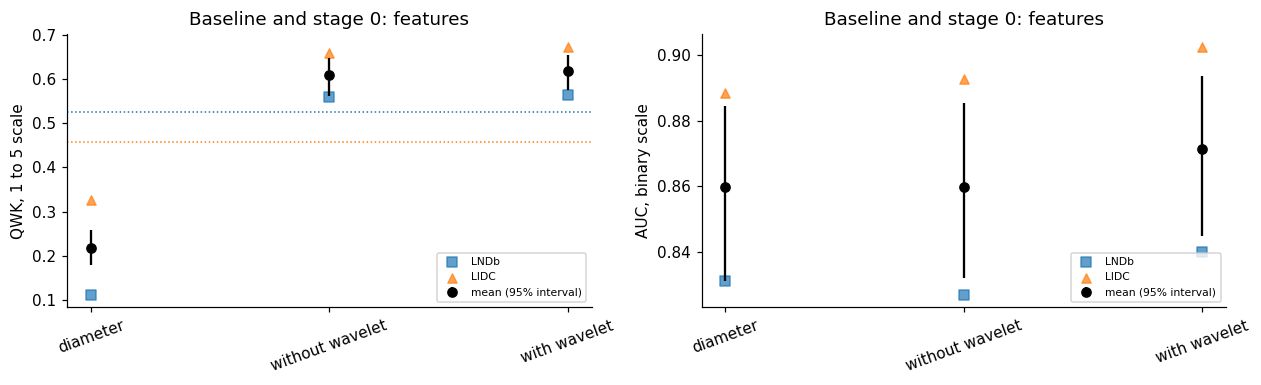

chosen features: without_wavelet


,mean_qwk,low,high,qwk_LNDb,qwk_LIDC,balanced_accuracy_LNDb,balanced_accuracy_LIDC,mae_LNDb,mae_LIDC,difference,difference_low,difference_high
config,,,,,,,,,,,,
baseline_diameter,0.218,0.180,0.257,0.111,0.325,0.284,0.312,0.911,0.650,-0.39,-0.432,-0.345
features_without_wavelet,0.608,0.561,0.646,0.558,0.658,0.413,0.445,0.601,0.482,0.00,0.000,0.000
features_with_wavelet,0.618,0.575,0.654,0.563,0.673,0.397,0.456,0.601,0.477,0.01,-0.002,0.023


,mean_auc,auc_low,auc_high,auc_LNDb,auc_LIDC,sensitivity_LNDb,sensitivity_LIDC,specificity_LNDb,specificity_LIDC,auc_difference,auc_difference_low,auc_difference_high
config,,,,,,,,,,,,
baseline_diameter,0.860,0.831,0.885,0.831,0.888,0.576,0.817,0.863,0.813,-0.000,-0.016,0.016
features_without_wavelet,0.860,0.832,0.885,0.827,0.893,0.481,0.810,0.911,0.867,0.000,0.000,0.000
features_with_wavelet,0.871,0.845,0.894,0.840,0.903,0.549,0.844,0.851,0.820,0.011,0.005,0.018


In [6]:
# The diameter alone, and the ordinal model without and with the wavelet features (difference: against without wavelet)
keys = ["baseline_diameter", "features_without_wavelet", "features_with_wavelet"]
stage_figure(keys, "Baseline and stage 0: features")
print("chosen features:", chosen["features"])
display(stage_table(keys))
stage_table(keys, AUC_COLUMNS)

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
  The diameter alone reaches a mean QWK of only 0.218 (95% interval from 0.180 to 0.257), because with a single feature the most probable rating is 3 for 90% of the nodules. On the binary scale, however, it reaches a mean AUC of 0.860, exactly the value of the ordinal model on the 63 features (difference 0.000, from 0.016 lower to 0.016 higher). Size decides almost alone whether a nodule is suspicious, as in clinical practice (MacMahon et al., 2017), while the intensity, texture and shape features are what place a nodule on the right rating of the scale: the ordinal model on the 63 features reaches 0.608 (from 0.561 to 0.646), 0.390 more than the diameter alone.
  </p>
  <p>
  The wavelet features raise the mean QWK to 0.618, 0.010 more, but the interval of the difference goes from 0.002 lower to 0.023 higher and includes zero, so by the rule fixed in advance the <strong>63 features without the wavelet images</strong> are kept. On the binary scale the wavelet features add a little (mean AUC 0.871 against 0.860, a difference of 0.011 from 0.005 to 0.018), but the primary metric of this stage is the QWK. Notebook 05 showed why the gain is small and risky: the wavelet features largely repeat what the LoG features measure, and many of them differ strongly between the two datasets. The section on a new hospital shows what they cost when the model moves from one dataset to the other.
  </p>
</div>

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   Stage 1: how to use LNDb and LIDC IDRI together
  </h3>
  <p>
  LNDb alone has 622 nodules and only 18 rated 5; LIDC IDRI adds 2615 nodules and 176 rated 5. The two datasets come from different scanners and different reading habits (46% of the LIDC IDRI nodules are rated 3, against 33% in LNDb), so pooling them can help or hurt. With the ordinal model, we compare:
  </p>
  <ul style="padding-left: 20px; margin-bottom: 20px;">
    <li style="margin-bottom: 8px;"><strong>each dataset alone</strong>, as a reference;</li>
    <li style="margin-bottom: 8px;"><strong>plain pooling</strong>, both datasets as they are;</li>
    <li style="margin-bottom: 8px;"><strong>a dataset indicator</strong>, one more column that lets the model shift its thresholds for LIDC IDRI;</li>
    <li style="margin-bottom: 8px;"><strong>ComBat harmonisation</strong> (Johnson et al., 2007; Orlhac et al., 2022) with LIDC IDRI as the reference batch, because it is the larger dataset: the LNDb features are moved onto the scale of LIDC IDRI, which stays unchanged (Zhang et al., 2018). The log diameter of the consensus region is kept as the biological covariate, so that size differences between the datasets are not removed as if they were scanner effects, and the rating is not used. ComBat is fitted on the training part of every fold only;</li>
    <li style="margin-bottom: 8px;"><strong>aggregation</strong>, one model per dataset and the average of their probabilities, each model with its own penalty, because LNDb has four times fewer nodules than LIDC IDRI and noisier labels.</li>
  </ul>
</div>

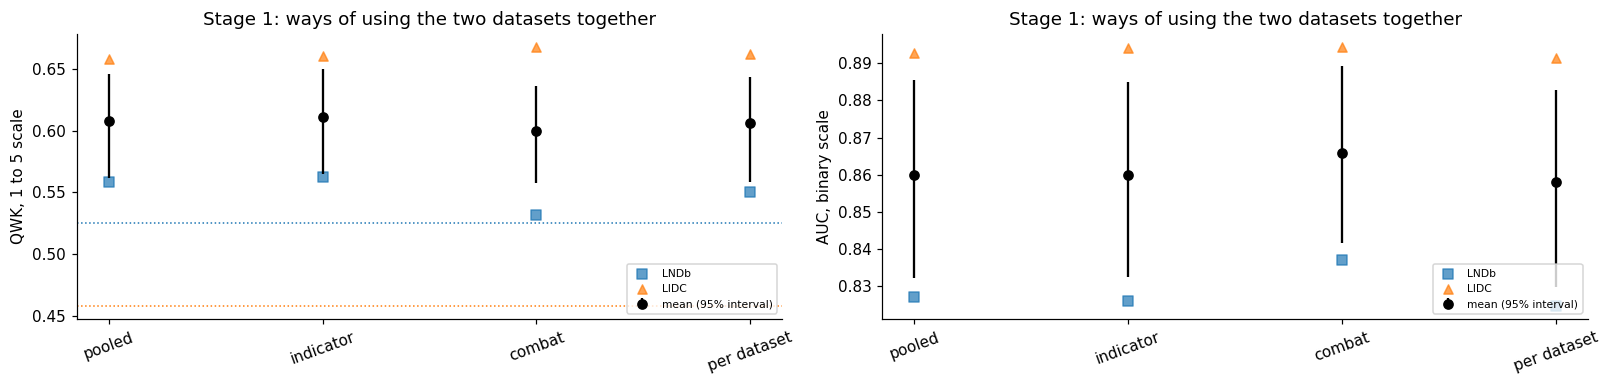

chosen: pooled


,mean_qwk,low,high,qwk_LNDb,qwk_LIDC,balanced_accuracy_LNDb,balanced_accuracy_LIDC,mae_LNDb,mae_LIDC,difference,difference_low,difference_high
config,,,,,,,,,,,,
pooling_LNDb_only,0.535,0.462,0.604,0.535,NaN,0.391,NaN,0.600,NaN,NaN,NaN,NaN
pooling_LIDC_only,0.676,0.642,0.708,NaN,0.676,NaN,0.473,NaN,0.469,NaN,NaN,NaN
pooling_pooled,0.608,0.561,0.646,0.558,0.658,0.413,0.445,0.601,0.482,0.000,0.000,0.000
pooling_indicator,0.611,0.565,0.650,0.562,0.660,0.415,0.448,0.598,0.481,0.003,-0.000,0.007
pooling_combat,0.600,0.557,0.636,0.531,0.668,0.405,0.458,0.637,0.477,-0.009,-0.026,0.009
pooling_per_dataset,0.606,0.558,0.644,0.550,0.662,0.410,0.444,0.609,0.482,-0.002,-0.011,0.006


,mean_auc,auc_low,auc_high,auc_LNDb,auc_LIDC,sensitivity_LNDb,sensitivity_LIDC,specificity_LNDb,specificity_LIDC,auc_difference,auc_difference_low,auc_difference_high
config,,,,,,,,,,,,
pooling_LNDb_only,0.831,0.781,0.875,0.831,NaN,0.818,NaN,0.695,NaN,NaN,NaN,NaN
pooling_LIDC_only,0.892,0.872,0.914,NaN,0.892,NaN,0.799,NaN,0.884,NaN,NaN,NaN
pooling_pooled,0.860,0.832,0.885,0.827,0.893,0.481,0.810,0.911,0.867,0.000,0.000,0.000
pooling_indicator,0.860,0.833,0.885,0.826,0.894,0.466,0.817,0.911,0.860,0.000,-0.002,0.002
pooling_combat,0.866,0.842,0.889,0.837,0.894,0.610,0.830,0.841,0.822,0.006,-0.003,0.014
pooling_per_dataset,0.858,0.830,0.883,0.825,0.892,0.496,0.828,0.900,0.834,-0.002,-0.005,0.001


In [7]:
keys = ["pooling_LNDb_only", "pooling_LIDC_only", "pooling_pooled", "pooling_indicator", "pooling_combat",
        "pooling_per_dataset"]
stage_figure(keys[2:], "Stage 1: ways of using the two datasets together")
print("chosen:", chosen["strategy"])
display(stage_table(keys))
stage_table(keys, AUC_COLUMNS)

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
  Each dataset alone reaches 0.535 in LNDb and 0.676 in LIDC IDRI. Plain pooling reaches 0.608, with 0.558 in LNDb and 0.658 in LIDC IDRI: LNDb gains 0.023 from the nodules of LIDC IDRI, which bring its 18 nodules rated 5 to 194 in training, while LIDC IDRI loses 0.018 because it now shares one model with a dataset that rates differently. No alternative beats plain pooling beyond the noise: the dataset indicator reaches 0.611 (an interval of the difference from just below zero to 0.007), ComBat 0.600 (from 0.026 lower to 0.009 higher, with its loss in LNDb, 0.531 against 0.558) and one model per dataset 0.606 (from 0.011 lower to 0.006 higher). By the rule fixed in advance, <strong>plain pooling</strong> is kept, the simplest option.
  </p>
</div>

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   How much regularisation the ordinal model needs
  </h3>
  <p>
  Every configuration chooses its hyperparameters in the inner folds. For the ordinal model the only hyperparameter is the penalty alpha, which shrinks the coefficients towards zero: a small alpha lets the model follow the training nodules closely, a large one keeps it simple. Its grid has ten values from 0.1 to 3000, evenly spaced on a logarithmic scale. Two checks show whether the choice was made well: the grid check fixed in advance, and the validation curve (Hastie et al., 2009), the inner score of every penalty averaged over the 15 outer folds, which shows whether the score has a peak inside the grid and how flat it is.
  </p>
</div>

In [8]:
# The grid check of the ordinal configurations: share of the outer folds whose chosen penalty is an end of its grid
ordinal_keys = ["baseline_diameter", "features_without_wavelet", "features_with_wavelet", "pooling_LNDb_only",
                "pooling_LIDC_only", "pooling_indicator", "pooling_combat", "pooling_per_dataset"]
print("largest share at an end of the grid:", summary.loc[ordinal_keys, "share_at_grid_edge"].round(2).to_dict())

# The penalties chosen by the two models of the aggregated configuration, in the 15 outer folds
penalties = pd.read_csv(MODEL_RESULTS_DIR / "pooling_per_dataset_choices.csv")
pd.crosstab(penalties["alpha_LNDb"], penalties["alpha_LIDC"], rownames=["penalty of the LNDb model"],
            colnames=["penalty of the LIDC IDRI model"])

largest share at an end of the grid: {'baseline_diameter': 0.0, 'features_without_wavelet': 0.0, 'features_with_wavelet': 0.0, 'pooling_LNDb_only': 0.0, 'pooling_LIDC_only': 0.0, 'pooling_indicator': 0.0, 'pooling_combat': 0.0, 'pooling_per_dataset': 0.0}


penalty of the LIDC IDRI model,10.0,30.0,100.0
penalty of the LNDb model,,,
30.0,0,0,1
100.0,0,1,1
300.0,0,5,2
1000.0,1,4,0


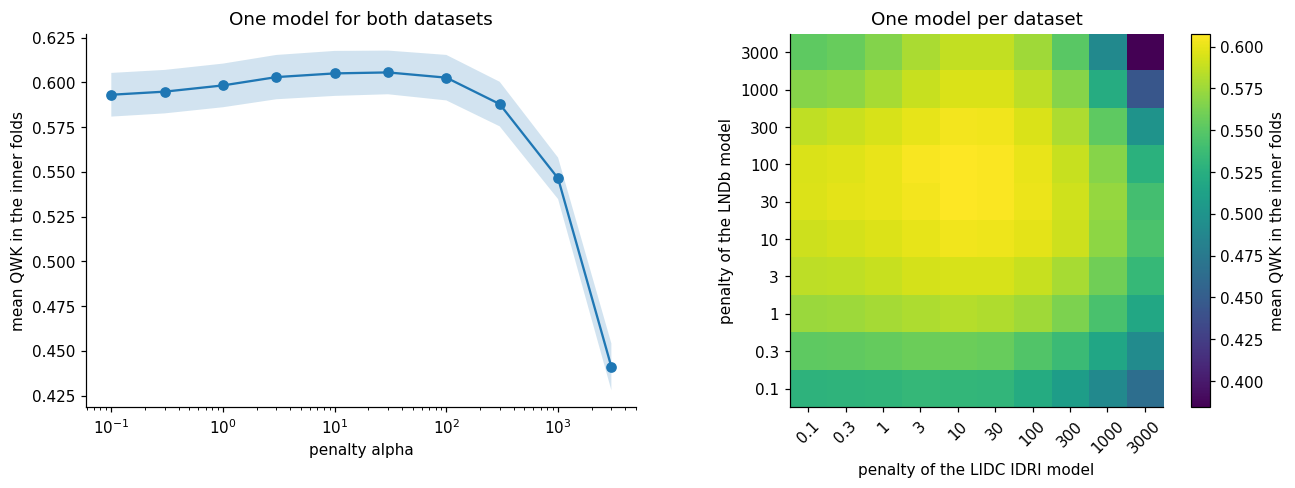

In [9]:
def inner_curve(key):
    """Inner score of every candidate of one configuration, averaged over the outer folds."""
    scores = pd.read_csv(MODEL_RESULTS_DIR / f"{key}_inner_scores.csv")
    curve = scores.groupby("params")[["score", "se"]].mean()
    curve["params"] = [json.loads(text) for text in curve.index]
    return curve

# Left: one model for both datasets, with one standard error around the mean inner score
pooled = inner_curve(features_key)
pooled["alpha"] = [params["alpha"] for params in pooled["params"]]
pooled = pooled.sort_values("alpha")

# Right: one model per dataset, every pair of penalties (LNDb, LIDC IDRI)
aggregated = inner_curve("pooling_per_dataset")
aggregated["LNDb"] = [params["LNDb"]["alpha"] for params in aggregated["params"]]
aggregated["LIDC"] = [params["LIDC"]["alpha"] for params in aggregated["params"]]
pairs = aggregated.pivot(index="LNDb", columns="LIDC", values="score")

fig, (left, right) = plt.subplots(1, 2, figsize=(12, 4.5))
left.plot(pooled["alpha"], pooled["score"], marker="o")
left.fill_between(pooled["alpha"], pooled["score"] - pooled["se"], pooled["score"] + pooled["se"], alpha=0.2)
left.set(xscale="log", xlabel="penalty alpha", ylabel="mean QWK in the inner folds", title="One model for both datasets")
image = right.imshow(pairs, cmap="viridis", origin="lower")
right.set_xticks(range(len(pairs.columns)), [f"{value:g}" for value in pairs.columns], rotation=45)
right.set_yticks(range(len(pairs.index)), [f"{value:g}" for value in pairs.index])
right.set(xlabel="penalty of the LIDC IDRI model", ylabel="penalty of the LNDb model", title="One model per dataset")
fig.colorbar(image, ax=right, label="mean QWK in the inner folds")
plt.tight_layout()
plt.show()

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
  The grid of the penalty is wide enough: no configuration of the ordinal model chose an end of its grid in any outer fold. The pooled model chose a penalty of 100 in 12 of the 15 outer folds and 300 in the other 3. Its validation curve is flat at the top: every penalty from 3 to 100 scores within 0.002 of the best (0.605 at 10 and 30), while the standard error of the inner score is about 0.012. Beyond 300 the score falls quickly (0.546 at 1000 and 0.441 at 3000), because the model is pushed towards the most frequent rating. The one standard error rule therefore chooses the strongest penalty of the flat top: within the noise of the inner folds it is as good as the best, and simpler. The map of the two penalties of the configuration with one model per dataset shows the same plateau, around 10 to 300 for LNDb and 3 to 100 for LIDC IDRI, so the result does not hinge on the exact value chosen.
  </p>
</div>

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   Stage 2: which model
  </h3>
  <p>
  With the chosen way of using the datasets, four models are compared: the ordinal logistic regression, a random forest, histogram gradient boosting and a support vector machine with an RBF kernel. The last three are nominal classifiers, which treat the ratings as unordered categories, so each is wrapped with the method of Frank and Hall (2001): four binary models answer &quot;is the rating above 1, 2, 3, 4?&quot;, and the probabilities of the ratings follow from their differences. A fair comparison needs every model tuned as carefully as the ordinal one, in the same inner loop:
  </p>
  <ul style="padding-left: 20px; margin-bottom: 20px;">
    <li style="margin-bottom: 8px;"><strong>Random forest:</strong> 15 candidates drawn at random (Bergstra and Bengio, 2012) from a grid of the share of features tried at each split (0.02 to 0.6), the size of the smallest leaf (1 to 40 nodules), the depth (8, 16 or unlimited) and an optional reweighting of the rare ratings, the hyperparameters that matter most for a forest (Probst, Wright and Boulesteix, 2019). The number of trees is not tuned, because more trees never make a forest worse (Probst and Boulesteix, 2018): 150 while comparing candidates and 500 in the final model.</li>
    <li style="margin-bottom: 8px;"><strong>Gradient boosting:</strong> 20 candidates drawn at random from the learning rate (0.01 to 0.2), the number of leaves of a tree (3 to 63), the size of the smallest leaf (10 to 100) and the L2 penalty (0.1 to 30); the number of rounds is set by early stopping on 20% of the training nodules.</li>
    <li style="margin-bottom: 8px;"><strong>Support vector machine:</strong> every pair of the penalty C (0.03 to 128) and the width gamma of the RBF kernel (0.0001 to 2), 56 candidates, because the two interact (Hsu, Chang and Lin, 2003).</li>
  </ul>
  <p>
  Every grid is ordered from the simplest value to the most complex one, so that the one standard error rule and the grid check apply to every model.
  </p>
</div>

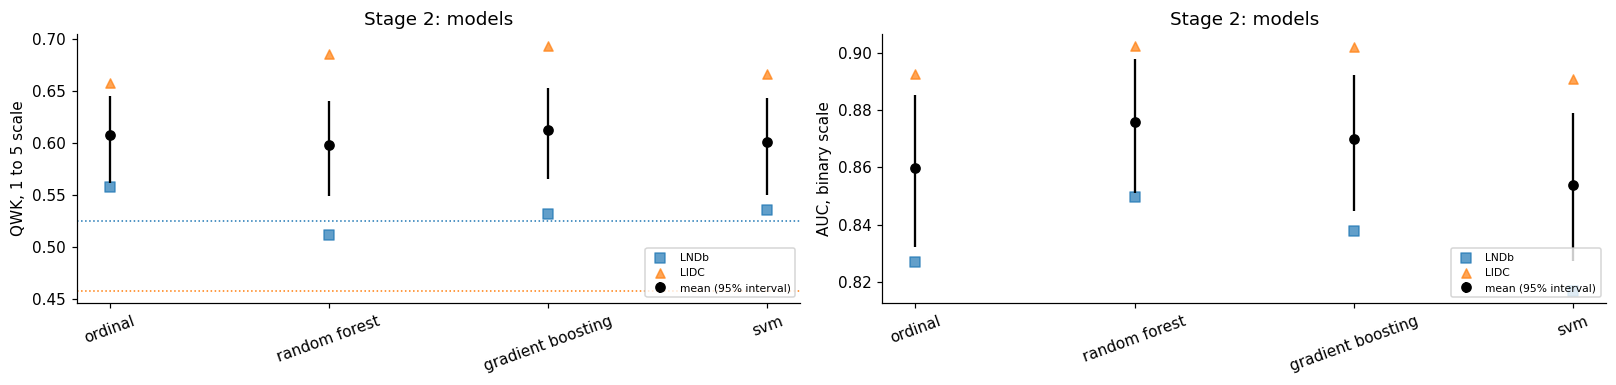

chosen: ordinal


,mean_qwk,low,high,qwk_LNDb,qwk_LIDC,balanced_accuracy_LNDb,balanced_accuracy_LIDC,mae_LNDb,mae_LIDC,difference,difference_low,difference_high
config,,,,,,,,,,,,
model_ordinal,0.608,0.561,0.646,0.558,0.658,0.413,0.445,0.601,0.482,0.000,0.000,0.000
model_random_forest,0.598,0.549,0.641,0.511,0.686,0.439,0.519,0.653,0.458,-0.010,-0.031,0.008
model_gradient_boosting,0.612,0.565,0.653,0.532,0.693,0.447,0.530,0.644,0.465,0.004,-0.017,0.026
model_svm,0.601,0.550,0.643,0.535,0.666,0.422,0.470,0.615,0.467,-0.007,-0.026,0.011


,mean_auc,auc_low,auc_high,auc_LNDb,auc_LIDC,sensitivity_LNDb,sensitivity_LIDC,specificity_LNDb,specificity_LIDC,auc_difference,auc_difference_low,auc_difference_high
config,,,,,,,,,,,,
model_ordinal,0.860,0.832,0.885,0.827,0.893,0.481,0.810,0.911,0.867,0.000,0.000,0.000
model_random_forest,0.876,0.851,0.898,0.850,0.902,0.705,0.848,0.803,0.805,0.016,0.003,0.030
model_gradient_boosting,0.870,0.845,0.892,0.838,0.902,0.716,0.859,0.772,0.799,0.010,-0.003,0.024
model_svm,0.854,0.827,0.879,0.817,0.891,0.602,0.800,0.861,0.856,-0.006,-0.020,0.007


In [10]:
keys = ["model_ordinal", "model_random_forest", "model_gradient_boosting", "model_svm"]
stage_figure(keys, "Stage 2: models")
print("chosen:", chosen["model"])
display(stage_table(keys))
stage_table(keys, AUC_COLUMNS)

In [11]:
# The hyperparameters chosen for the three other models: the value chosen most often in the 15 outer folds, and the
# share of folds at an end of its grid (the grid check; only numeric grids of three values or more are checked)
rows = []
for name in ("random_forest", "gradient_boosting", "svm"):
    choices = pd.read_csv(MODEL_RESULTS_DIR / f"model_{name}_choices.csv")
    chosen_values = pd.DataFrame([flat(json.loads(text)) for text in choices["params"]], dtype=object).astype(str)
    edges = edge_share(name, choices)
    for column in chosen_values:
        counts = chosen_values[column].value_counts()
        rows.append({"model": name.replace("_", " "), "hyperparameter": column, "chosen most often": counts.index[0],
                     "in folds": counts.iloc[0], "share at an end of the grid": edges.get(column, np.nan)})
pd.DataFrame(rows).set_index(["model", "hyperparameter"]).round(2)

chosen most often  in folds  share at an end of the grid
model             hyperparameter                                                            
random forest     min_samples_leaf                 20         7                         0.07
                  max_features                  0.035         7                         0.00
                  max_depth                         8         8                          NaN
                  class_weight                   None        15                          NaN
gradient boosting min_samples_leaf                100        12                         0.80
                  max_leaf_nodes                   15        12                         0.00
                  learning_rate                  0.01        15                         1.00
                  l2_regularization              30.0        12                         0.80
svm               C                               8.0         6                         0.07
                  gamma               0.0001220703125         7                         0.47

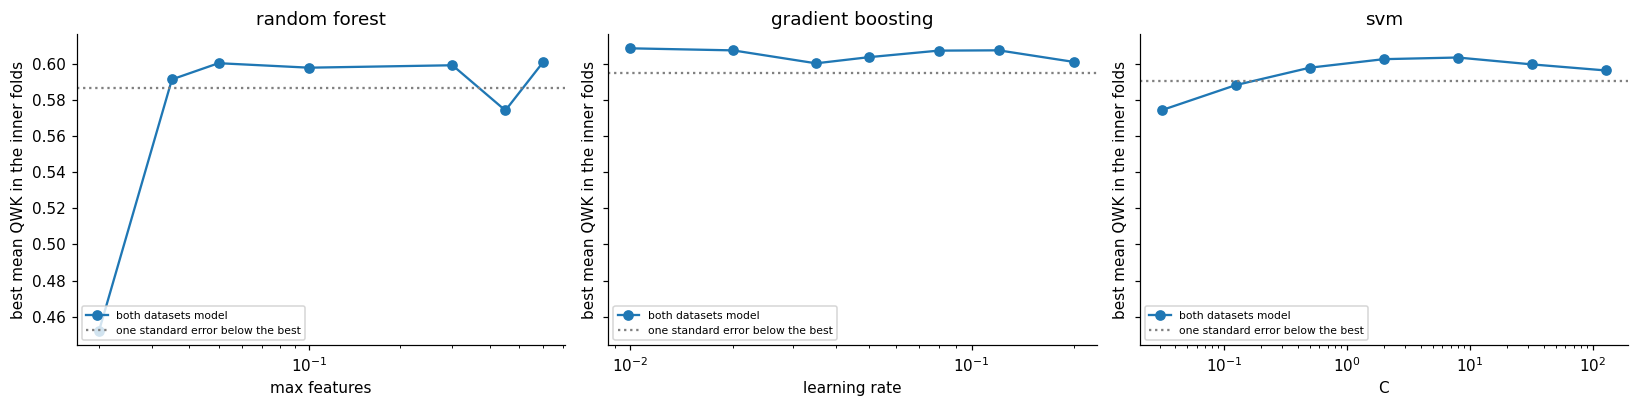

In [12]:
# Profile curves: for each value of the main hyperparameter of each model, the best inner score that a candidate with
# that value reaches (in each outer fold, then averaged over the 15 folds), for each dataset model. The dotted line is
# one standard error below the best score: every value above it is as good as the best within the noise.
main = {"random_forest": "max_features", "gradient_boosting": "learning_rate", "svm": "C"}
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
for axis, (name, key) in zip(axes, main.items()):
    scores = pd.read_csv(MODEL_RESULTS_DIR / f"model_{name}_inner_scores.csv")
    params = [json.loads(text) for text in scores["params"]]
    datasets = ("LNDb", "LIDC") if "LNDb" in params[0] else ("both datasets",)
    best_score = -np.inf
    for dataset in datasets:
        values = [own[dataset][key] if dataset in own else own[key] for own in params]
        best = scores.assign(value=values).groupby(["seed", "outer_fold", "value"])["score"].max()
        profile = best.groupby("value").mean()
        axis.plot(profile.index, profile.values, marker="o", label=f"{dataset} model")
        best_score = max(best_score, profile.max())
    axis.axhline(best_score - scores["se"].mean(), color="grey", linestyle=":", label="one standard error below the best")
    axis.set(xscale="log", xlabel=key.replace("_", " "), ylabel="best mean QWK in the inner folds", title=name.replace("_", " "))
    axis.legend(fontsize=7, loc="lower left")
plt.tight_layout()
plt.show()

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
  With every model tuned, gradient boosting reaches the highest mean QWK, 0.612 (from 0.565 to 0.653), but its difference to the ordinal model, 0.004, has an interval from 0.017 lower to 0.026 higher. The random forest (0.598) and the SVM (0.601) are within the noise as well. By the rule fixed in advance, the <strong>ordinal logistic regression</strong> is kept: it is the simplest model and its coefficients can be read directly.
  </p>
  <p>
  The comparison still shows where the flexible models differ. The tree models are better in LIDC IDRI (0.693 for boosting and 0.686 for the forest, against 0.658) and worse in LNDb (0.532 and 0.511 against 0.558), where 622 nodules are too few for a flexible model. On the binary scale the random forest is the only model above the ordinal one beyond the noise (mean AUC 0.876 against 0.860, a difference of 0.016 from 0.003 to 0.030), and the two tree models reach a much higher sensitivity in LNDb (0.705 and 0.716 against 0.481), at the cost of specificity.
  </p>
  <p>
  The grid check flags gradient boosting, whose smallest learning rate was chosen in every outer fold, and the SVM, whose smallest gamma was chosen in 47% of them. The profile curves show why: boosting scores between 0.600 and 0.608 at every learning rate, and the SVM between 0.600 and 0.603 at the four smallest values of gamma, all within a standard error of about 0.014. The one standard error rule picks the simplest end of a flat plateau, so a wider grid would not change the result. The random forest passes the check.
  </p>
</div>

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   Stage 3: the binary answer
  </h3>
  <p>
  The binary answer can come from the model of the 1 to 5 scale, whose probability of a rating of 4 or 5 is already the probability of a suspicious nodule, or from a model trained directly on the binary label. The first keeps one model for both scales and learns from the full detail of the rating; the second concentrates on the single question that the binary scale asks. The direct model is the chosen model of stage 2 trained on the binary label, with its hyperparameters chosen in the inner folds by the log loss: the AUC only depends on the order of the nodules, which a penalty barely changes, so it cannot tell a useful penalty from one that shrinks every coefficient to almost nothing, while the log loss also judges the probabilities themselves (Gneiting and Raftery, 2007). The primary metric of this stage is the mean AUC, and the threshold of both is chosen in the inner folds.
  </p>
</div>

chosen: from_1_to_5


,mean_auc,auc_low,auc_high,auc_LNDb,auc_LIDC,sensitivity_LNDb,sensitivity_LIDC,specificity_LNDb,specificity_LIDC,auc_difference,auc_difference_low,auc_difference_high
config,,,,,,,,,,,,
binary_from_1_to_5,0.860,0.832,0.885,0.827,0.893,0.481,0.810,0.911,0.867,0.000,0.000,0.000
binary_direct,0.869,0.843,0.892,0.842,0.895,0.572,0.838,0.878,0.811,0.009,-0.003,0.021


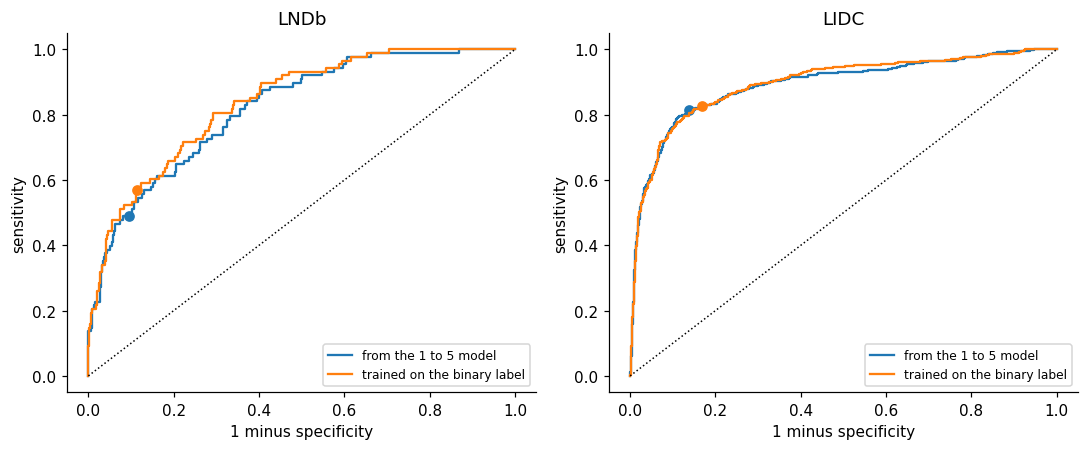

In [13]:
keys = ["binary_from_1_to_5", "binary_direct"]
print("chosen:", chosen["binary"])
display(stage_table(keys, AUC_COLUMNS))

# ROC curves of the two ways (first seed), per dataset, with the point of the threshold chosen in the inner folds
results = {"from the 1 to 5 model": load_result(stage2_key),
           "trained on the binary label": load_result(f"binary_direct_{chosen['model']}_{chosen['strategy']}")}
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
for axis, dataset in zip(axes, ("LNDb", "LIDC")):
    rows = (nodules["dataset"] == dataset).to_numpy()
    y = nodules["suspicious"].to_numpy()[rows]
    for name, result in results.items():
        false_positive, true_positive, _ = roc_curve(y, result["suspicious_proba"][0][rows])
        line, = axis.plot(false_positive, true_positive, label=name)
        flagged = result["suspicious_pred"][0][rows]
        axis.plot(flagged[y == 0].mean(), flagged[y == 1].mean(), "o", color=line.get_color())
    axis.plot([0, 1], [0, 1], "k:", linewidth=1)
    axis.set(xlabel="1 minus specificity", ylabel="sensitivity", title=dataset)
    axis.legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.show()

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
  A model trained directly on the binary label does not beat the probability given by the 1 to 5 model: a mean AUC of 0.869 against 0.860, a difference of 0.009 with an interval from 0.003 lower to 0.021 higher. By the rule fixed in advance, the binary answer comes <strong>from the 1 to 5 model</strong>, so one model serves both scales, and learning the detailed rating costs nothing on the binary question.
  </p>
  <p>
  The two ROC curves almost overlap. What the figure does show is the real difficulty of the binary answer, which is not the ranking but the threshold: one threshold for both datasets gives a sensitivity of 0.810 in LIDC IDRI but only 0.481 in LNDb, with a specificity of 0.867 and 0.911. The suspicious nodules of LNDb are smaller than those of LIDC IDRI (median diameter 8.5 against 11.9 mm) and get lower probabilities (0.41 against 0.62 on average), so a threshold that balances sensitivity and specificity over both datasets is too high for LNDb. The confirmation and the section on a new hospital come back to this.
  </p>
</div>

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   Stage 4: three extensions of the chosen model
  </h3>
  <p>
  Three extensions of the chosen configuration address its known weaknesses, each with its hyperparameters chosen in the inner folds:
  </p>
  <ul style="padding-left: 20px; margin-bottom: 20px;">
    <li style="margin-bottom: 8px;"><strong>Rare ratings weighted up:</strong> the ordinal model trained with every nodule weighted by one divided by the share of its rating, raised to a power of 0 (no change), 0.5 or 1 (every rating weighs the same in total), so that the model can predict more 4s and 5s.</li>
    <li style="margin-bottom: 8px;"><strong>Elastic net:</strong> a logistic regression with an L1 and an L2 penalty (Zou and Hastie, 2005), wrapped with the method of Frank and Hall. The L1 part sets the coefficients of unhelpful features exactly to zero, so it selects features inside every fit, with the rating, but only on the training part of each fold (Ambroise and McLachlan, 2002).</li>
    <li style="margin-bottom: 8px;"><strong>Average of the ordinal model and the random forest:</strong> for each dataset, w times the probabilities of the ordinal model plus (1 minus w) times those of the forest, with w from 1 to 0. A weighted average is a constrained form of stacking, the most stable one when data are few (Breiman, 1996); each model keeps the hyperparameters that its own inner loop chose in that outer fold. It needs one model per dataset, so it only runs when stage 1 keeps that way of pooling.</li>
  </ul>
  <p>
  Each extension replaces the chosen configuration only if the 95% interval of its difference lies above zero.
  </p>
</div>

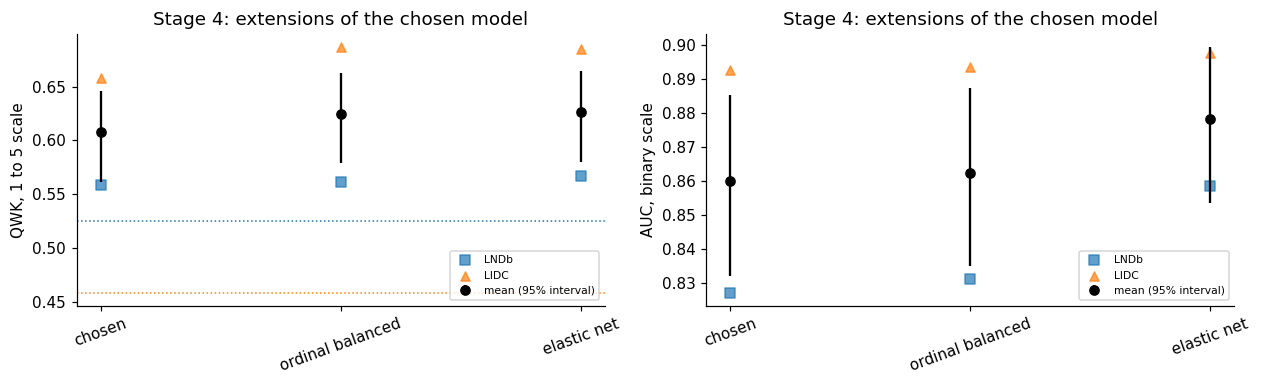

final model: ordinal_balanced


,mean_qwk,low,high,qwk_LNDb,qwk_LIDC,balanced_accuracy_LNDb,balanced_accuracy_LIDC,mae_LNDb,mae_LIDC,difference,difference_low,difference_high
config,,,,,,,,,,,,
extension_chosen,0.608,0.561,0.646,0.558,0.658,0.413,0.445,0.601,0.482,0.000,0.000,0.000
extension_ordinal_balanced,0.624,0.579,0.663,0.561,0.687,0.432,0.509,0.615,0.495,0.016,0.002,0.032
extension_elastic_net,0.626,0.579,0.665,0.567,0.685,0.439,0.509,0.600,0.454,0.018,-0.000,0.035


,mean_auc,auc_low,auc_high,auc_LNDb,auc_LIDC,sensitivity_LNDb,sensitivity_LIDC,specificity_LNDb,specificity_LIDC,auc_difference,auc_difference_low,auc_difference_high
config,,,,,,,,,,,,
extension_chosen,0.860,0.832,0.885,0.827,0.893,0.481,0.810,0.911,0.867,0.000,0.000,0.000
extension_ordinal_balanced,0.862,0.835,0.887,0.831,0.894,0.504,0.830,0.898,0.844,0.003,0.001,0.004
extension_elastic_net,0.878,0.853,0.900,0.859,0.898,0.614,0.837,0.863,0.821,0.018,0.006,0.030


In [14]:
keys = [key for key in ("extension_chosen", "extension_ordinal_balanced", "extension_elastic_net", "extension_ordinal_rf")
        if key in summary.index]
stage_figure(keys, "Stage 4: extensions of the chosen model")
print("final model:", chosen["final_model"])
display(stage_table(keys))
stage_table(keys, AUC_COLUMNS)

In [15]:
# What the inner folds chose for each extension, in the 15 outer folds
weighted = pd.read_csv(MODEL_RESULTS_DIR / "extension_ordinal_balanced_choices.csv")
power_columns = [column for column in weighted if column.startswith("class_power")]
display(weighted[power_columns].apply(lambda column: column.value_counts()).fillna(0).astype(int)
        .rename_axis("power of the class weights"))
if (MODEL_RESULTS_DIR / "extension_ordinal_rf_choices.csv").exists():
    average = pd.read_csv(MODEL_RESULTS_DIR / "extension_ordinal_rf_choices.csv")
    display(pd.crosstab(average["w_LNDb"], average["w_LIDC"], rownames=["weight of the ordinal model, LNDb"],
                        colnames=["weight of the ordinal model, LIDC IDRI"]))

# Elastic net: how many features keep a non zero coefficient, refitted on every nodule of each dataset with the
# hyperparameters chosen most often (a description of the selection, not an evaluation)
features = feature_sets[chosen["features"]]
net = pd.read_csv(MODEL_RESULTS_DIR / "extension_elastic_net_choices.csv")
for dataset in ("LNDb", "LIDC"):
    params = json.loads(net["params"].mode()[0])
    params = params.get(dataset, params)
    rows = nodules[nodules["dataset"] == dataset]
    model = make_model("elastic_net", params).fit(rows[features], rows["rating"])
    used = np.any([binary.coef_[0] != 0 for binary in model[-1].models_], axis=0)
    print(f"{dataset}: C {params['C']}, L1 share {params['l1_ratio']}: {used.sum()} of {len(features)} features kept")

,class_power
power of the class weights,
0.5,15


LNDb: C 0.1, L1 share 1.0: 23 of 63 features kept


LIDC: C 0.1, L1 share 1.0: 45 of 63 features kept


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
  Weighting the rare ratings up is the only extension that beats the chosen configuration beyond the noise: 0.624 (from 0.579 to 0.663), 0.016 more, with an interval from 0.002 to 0.032. Its gain is almost all in LIDC IDRI (0.687 against 0.658, and 0.561 against 0.558 in LNDb), and its balanced accuracy rises (0.432 in LNDb and 0.509 in LIDC IDRI, against 0.413 and 0.445), at the cost of a slightly larger MAE (0.615 and 0.495 against 0.601 and 0.482). The inner folds chose a power of 0.5 in every outer fold, half way between no weights and every rating weighing the same.
  </p>
  <p>
  The elastic net reaches a slightly higher mean (0.626), but its interval starts just below zero (from 0.000 lower to 0.035 higher). On the binary scale it is the best option of the whole notebook (mean AUC 0.878, 0.018 above the chosen configuration, from 0.006 to 0.030), while it keeps only 23 of the 63 features when refitted on LNDb and 45 on LIDC IDRI: a sparser model ranks the nodules a little better. The average with the random forest needs one model per dataset, so it does not apply after stage 1 kept a single model for both.
  </p>
  <p>
  By the rule fixed in advance, the <strong>ordinal model with the rare ratings weighted up</strong> becomes the final configuration. Two extensions were tried, which raises the risk of a gain by chance; the confirmation on new seeds below is the safeguard.
  </p>
</div>

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   The chosen configuration on new splits
  </h3>
  <p>
  Every stage chose among options on the same outer folds, which makes the reported score slightly optimistic. The chosen configuration is therefore evaluated again on three new seeds, which it never saw while being chosen. Its agreement with every single radiologist (each reading weighted by one over the number of readers of its nodule) is shown as well, because it does not depend on how the readers were combined into the label.
  </p>
</div>

In [16]:
confirmation = load_result(f"confirmation_{final_tag}")
reader_columns = ["reader_qwk_LNDb", "reader_qwk_LIDC", "reader_auc_LNDb", "reader_auc_LIDC"]
display(stage_table([final_key, "confirmation"]))
display(stage_table([final_key, "confirmation"], AUC_COLUMNS))
summary.loc[["confirmation"], reader_columns].round(3)

,mean_qwk,low,high,qwk_LNDb,qwk_LIDC,balanced_accuracy_LNDb,balanced_accuracy_LIDC,mae_LNDb,mae_LIDC,difference,difference_low,difference_high
config,,,,,,,,,,,,
extension_ordinal_balanced,0.624,0.579,0.663,0.561,0.687,0.432,0.509,0.615,0.495,0.016,0.002,0.032
confirmation,0.621,0.576,0.661,0.557,0.686,0.432,0.507,0.613,0.492,NaN,NaN,NaN


,mean_auc,auc_low,auc_high,auc_LNDb,auc_LIDC,sensitivity_LNDb,sensitivity_LIDC,specificity_LNDb,specificity_LIDC,auc_difference,auc_difference_low,auc_difference_high
config,,,,,,,,,,,,
extension_ordinal_balanced,0.862,0.835,0.887,0.831,0.894,0.504,0.83,0.898,0.844,0.003,0.001,0.004
confirmation,0.861,0.833,0.886,0.831,0.892,0.504,0.82,0.903,0.846,NaN,NaN,NaN


,reader_qwk_LNDb,reader_qwk_LIDC,reader_auc_LNDb,reader_auc_LIDC
config,,,,
confirmation,0.533,0.555,0.833,0.823


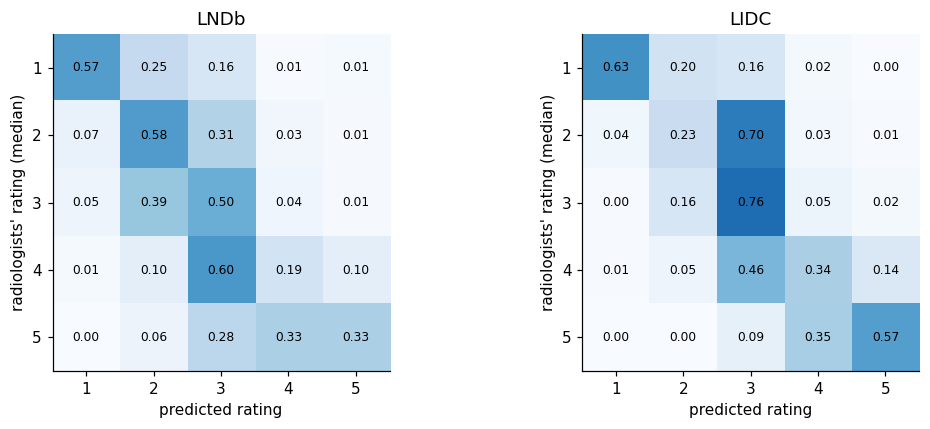

In [17]:
# Confusion matrices of the chosen configuration (first new seed), per dataset; each row sums to 1
decoded = confirmation["decoded"][0]
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for axis, dataset in zip(axes, ("LNDb", "LIDC")):
    rows = (nodules["dataset"] == dataset).to_numpy()
    matrix = confusion_matrix(nodules["rating"][rows], decoded[rows], labels=range(1, 6), normalize="true")
    axis.imshow(matrix, cmap="Blues", vmin=0, vmax=1)
    for i in range(5):
        for j in range(5):
            axis.text(j, i, f"{matrix[i, j]:.2f}", ha="center", va="center", fontsize=8)
    axis.set(xticks=range(5), xticklabels=range(1, 6), yticks=range(5), yticklabels=range(1, 6),
             xlabel="predicted rating", ylabel="radiologists' rating (median)", title=dataset)
plt.tight_layout()
plt.show()

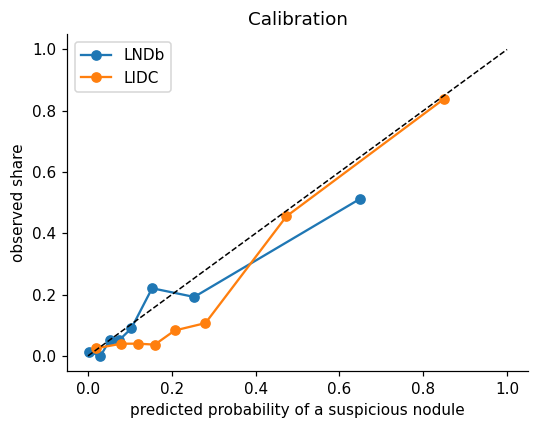

In [18]:
# Calibration: predicted probability of a suspicious nodule against the observed share, in 8 groups of equal size
# (probabilities averaged over the three new seeds)
probability = confirmation["suspicious_proba"].mean(axis=0)
is_suspicious = nodules["suspicious"].to_numpy()
fig, ax = plt.subplots(figsize=(5, 4))
for dataset in ("LNDb", "LIDC"):
    rows = (nodules["dataset"] == dataset).to_numpy()
    groups = pd.qcut(probability[rows], 8, duplicates="drop")
    predicted = pd.Series(probability[rows]).groupby(groups).mean()
    observed = pd.Series(is_suspicious[rows]).groupby(groups).mean()
    ax.plot(predicted, observed, marker="o", label=dataset)
ax.plot([0, 1], [0, 1], "k--", linewidth=1)          # perfect calibration
ax.set(xlabel="predicted probability of a suspicious nodule", ylabel="observed share", title="Calibration")
ax.legend()
plt.tight_layout()
plt.show()

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
  On three new seeds the final configuration reaches a mean QWK of 0.621 (from 0.576 to 0.661), with 0.557 in LNDb and 0.686 in LIDC IDRI, against 0.624 on the seeds used for choosing: the choices made the estimate only about 0.003 optimistic, much less than its uncertainty. Its agreement with every single radiologist is a QWK of 0.533 in LNDb and 0.555 in LIDC IDRI, as high as the agreement of one radiologist with the median of the others (0.527 and 0.528). On the binary scale it reaches a mean AUC of 0.861 (from 0.833 to 0.886).
  </p>
  <p>
  Most errors are of one rating, and large errors are rare: a nodule rated 1 is predicted 4 or 5 in 2% of the cases, and a nodule rated 5 is never predicted 1. The model is still drawn towards rating 3 for many nodules: in LIDC IDRI 70% of the nodules rated 2 and 46% of those rated 4 are predicted 3, and in LNDb 60% of those rated 4. The rare ratings are still found: 34% of the LIDC IDRI nodules rated 4 and 57% of those rated 5 are predicted exactly, and 33% of the LNDb nodules rated 5.
  </p>
  <p>
  With the threshold chosen in the inner folds (between 0.24 and 0.34 in the 15 outer folds), the model flags 82% of the suspicious nodules of LIDC IDRI with a specificity of 0.846, but only 50% of those of LNDb, with a specificity of 0.903. Keeping in mind that a radiologist is compared with the median of the other readers and the model with the median of all of them, this is more sensitive than one radiologist in LIDC IDRI (0.509 at a specificity of 0.829) and about the same in LNDb (0.494 at 0.902). The gap between the datasets is a matter of the threshold rather than of the ranking (the AUC is 0.831 in LNDb and 0.892 in LIDC IDRI).
  </p>
  <p>
  The probabilities are somewhat too high, as expected from the weights, which tell the model that the rare ratings are more frequent than they are: the mean predicted probability of a suspicious nodule is 0.165 in LNDb and 0.273 in LIDC IDRI, against observed shares of 0.141 and 0.203. The excess sits in the middle of the range: in LIDC IDRI the nodules given probabilities between 0.10 and 0.34 are suspicious in only 4% to 11% of the cases, while the highest group (0.85) matches its observed share (0.84). The predicted rating is better with the weights, but the probabilities should not be read as risks without a recalibration fitted on the training folds (Van Calster et al., 2019).
  </p>
</div>

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   A new hospital: trained on one dataset, validated on the other
  </h3>
  <p>
  The cross validation above always trains on both datasets, so every hospital, scanner and group of readers is already known to the model. A hospital that adopts the model would not be: its scanners, protocols and radiologists would be new. To measure this, the model is trained on every nodule of one dataset and validated on every nodule of the other (Steyerberg and Harrell, 2016). The direction from LIDC IDRI to LNDb is the main one: LNDb was built as an external set for models trained on LIDC IDRI (Pedrosa et al., 2019), and it is the case of a hospital that receives a model trained elsewhere. The other direction shows what happens when a model is trained on few nodules from a single hospital. Models that do well inside their own data often lose performance in another hospital (Zech et al., 2018).
  </p>
  <ul style="padding-left: 20px; margin-bottom: 20px;">
    <li style="margin-bottom: 8px;"><strong>How the model is trained.</strong> The final model, with its hyperparameters and its threshold chosen in inner folds of the source dataset only, grouped by patient, with three seeds. The other dataset never takes part in any choice.</li>
    <li style="margin-bottom: 8px;"><strong>The reference.</strong> The same model in cross validation inside the dataset that is predicted, which is what that hospital would reach with its own data. The loss of generalisation is the difference between the two, on the same nodules, with an interval from resampling their patients.</li>
    <li style="margin-bottom: 8px;"><strong>Three sets of features.</strong> The diameter alone, which depends little on the scanner, the 63 features without the wavelet images and the 169 with them. If the loss grows from one set to the next, it comes from the texture features, which depend more on the scanner.</li>
    <li style="margin-bottom: 8px;"><strong>Harmonisation.</strong> A variant in which the features of the new hospital are first moved onto the scale of the source dataset with ComBat, using only the scans of the new hospital and no rating (Orlhac et al., 2022), which a hospital could do in practice.</li>
    <li style="margin-bottom: 8px;"><strong>Ranking or scale.</strong> The AUC only depends on the order of the nodules, and the QWK also depends on where the model places them on the scale. If the AUC holds while the QWK drops, the model still ranks the nodules well, and the loss comes from the different rating habits of the two groups of radiologists rather than from the features.</li>
  </ul>
</div>

In [19]:
# For every direction and set of features: the same model inside the predicted dataset (cross validation) and trained
# on the other dataset; the difference is external minus inside, on the same nodules
rows = []
for source, target in (("LIDC", "LNDb"), ("LNDb", "LIDC")):
    for set_name in ("diameter", "without_wavelet", "with_wavelet", "combat"):
        external = summary.loc[f"external_{source}_to_{target}_{set_name}"]
        within = summary.loc[f"within_{target}_{set_name}"] if set_name != "combat" else None
        rows.append({
            "trained on": source, "validated on": target, "features": set_name.replace("_", " "),
            "QWK inside": within["mean_qwk"] if within is not None else np.nan,
            "QWK external": external["mean_qwk"],
            "difference": external["difference"], "low": external["difference_low"], "high": external["difference_high"],
            "AUC inside": within["mean_auc"] if within is not None else np.nan,
            "AUC external": external["mean_auc"],
            "AUC difference": external["auc_difference"],
            "AUC low": external["auc_difference_low"], "AUC high": external["auc_difference_high"],
            f"sensitivity": external[f"sensitivity_{target}"], f"specificity": external[f"specificity_{target}"],
        })
new_hospital = pd.DataFrame(rows).set_index(["trained on", "validated on", "features"])
print(f"combat: the chosen features ({chosen['features'].replace('_', ' ')}) harmonised; its difference is against the "
      "same features without harmonisation")
new_hospital.round(3)

combat: the chosen features (without wavelet) harmonised; its difference is against the same features without harmonisation


QWK inside  QWK external  difference    low   high  AUC inside  AUC external  AUC difference  AUC low  AUC high  \
trained on validated on features                                                                                                                           
LIDC       LNDb         diameter              0.377         0.357      -0.021 -0.054  0.011       0.746         0.833           0.087    0.057     0.120   
                        without wavelet       0.546         0.541      -0.005 -0.038  0.026       0.827         0.828           0.001   -0.015     0.016   
                        with wavelet          0.539         0.557       0.019 -0.020  0.058       0.809         0.831           0.021   -0.002     0.042   
                        combat                  NaN         0.556       0.015 -0.002  0.035         NaN         0.845           0.018    0.007     0.030   
LNDb       LIDC         diameter              0.444         0.474       0.030  0.015  0.045       0.877         0.890           0.012    0.005     0.021   
                        without wavelet       0.690         0.650      -0.040 -0.055 -0.023       0.892         0.884          -0.008   -0.016    -0.000   
                        with wavelet          0.702         0.615      -0.087 -0.106 -0.071       0.903         0.871          -0.032   -0.042    -0.022   
                        combat                  NaN         0.650       0.000 -0.015  0.015         NaN         0.889           0.006    0.003     0.008   

                                         sensitivity  specificity  
trained on validated on features                                   
LIDC       LNDb         diameter               0.534        0.898  
                        without wavelet        0.542        0.892  
                        with wavelet           0.583        0.832  
                        combat                 0.595        0.870  
LNDb       LIDC         diameter               0.899        0.669  
                        without wavelet        0.962        0.321  
                        with wavelet           0.873        0.591  
                        combat                 0.921        0.561

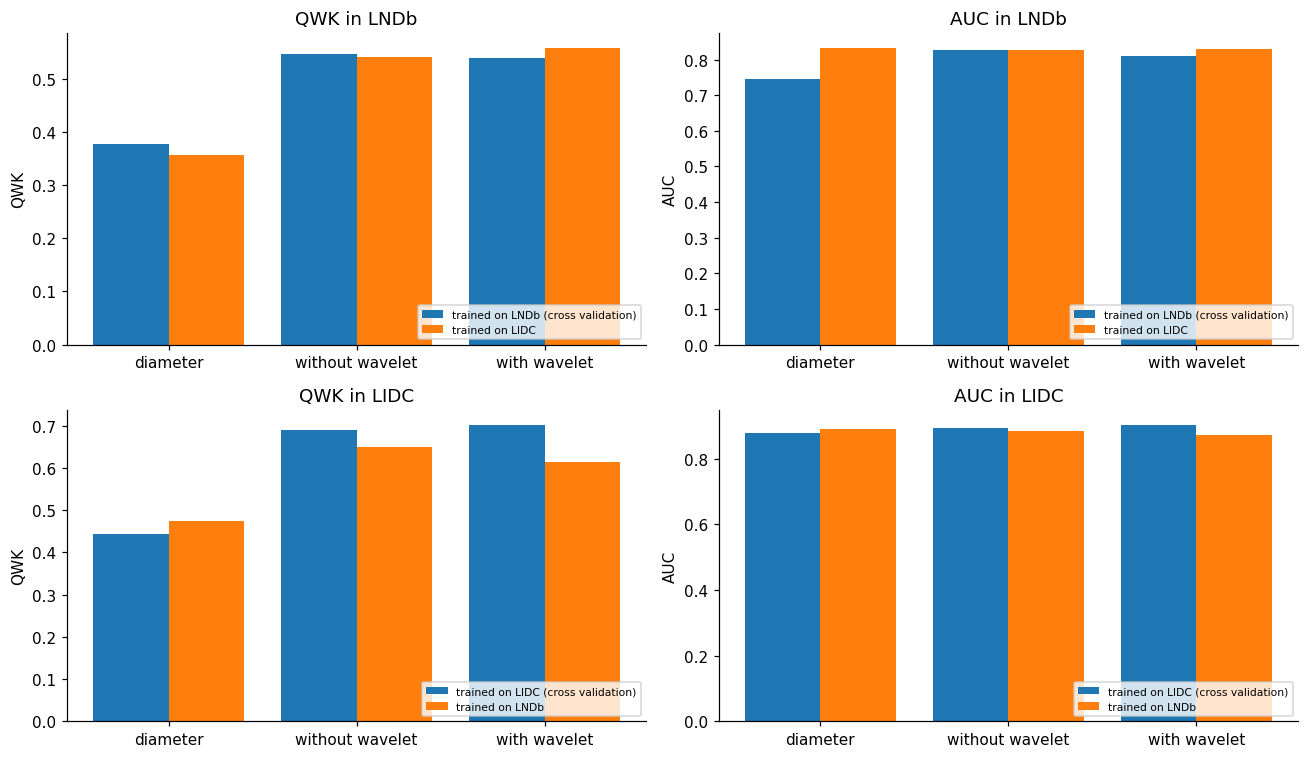

In [20]:
# QWK and AUC inside each dataset and from the other dataset, for each set of features
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for row_axes, (source, target) in zip(axes, (("LIDC", "LNDb"), ("LNDb", "LIDC"))):
    part = new_hospital.loc[(source, target)].drop(index="combat")
    x = np.arange(len(part))
    for axis, metric in zip(row_axes, ("QWK", "AUC")):
        axis.bar(x - 0.2, part[f"{metric} inside"], 0.4, label=f"trained on {target} (cross validation)")
        axis.bar(x + 0.2, part[f"{metric} external"], 0.4, label=f"trained on {source}")
        axis.set_xticks(x, part.index)
        axis.set(ylabel=metric, title=f"{metric} in {target}")
        axis.legend(fontsize=7, loc="lower right")
plt.tight_layout()
plt.show()

In [21]:
# Rating habits: the share of each rating predicted for the new hospital, against the share in its own labels
rows = {}
for source, target in (("LIDC", "LNDb"), ("LNDb", "LIDC")):
    external = load_result(f"external_{source}_to_{target}_{chosen['features']}_{external_model}")
    within = load_result(f"within_{target}_{chosen['features']}_{external_model}")
    observed = nodules.loc[nodules["dataset"] == target, "rating"]
    rows[(target, "radiologists")] = observed.value_counts(normalize=True)
    rows[(target, f"trained on {target}")] = pd.Series(within["decoded"].ravel()).value_counts(normalize=True)
    rows[(target, f"trained on {source}")] = pd.Series(external["decoded"].ravel()).value_counts(normalize=True)
pd.DataFrame(rows).T.reindex(columns=range(1, 6)).fillna(0).round(2)

1     2     3     4     5
LNDb radiologists     0.23  0.31  0.33  0.11  0.03
     trained on LNDb  0.13  0.41  0.38  0.07  0.02
     trained on LIDC  0.20  0.40  0.25  0.09  0.05
LIDC radiologists     0.12  0.21  0.46  0.14  0.07
     trained on LIDC  0.10  0.19  0.54  0.11  0.07
     trained on LNDb  0.06  0.15  0.57  0.14  0.09

In [22]:
# Where the external model fails: mean absolute error by size of the nodule, inside the dataset and from the other one
size_groups = [0, 5, 8, 12, 100]
size_names = ["under 5 mm", "5 to 8", "8 to 12", "12 mm or more"]
rows = {}
for source, target in (("LIDC", "LNDb"), ("LNDb", "LIDC")):
    part = nodules[nodules["dataset"] == target].reset_index(drop=True)
    size = pd.cut(part["roi_diameter_mm"], size_groups, labels=size_names)
    for name, key in ((f"trained on {target}", f"within_{target}_{chosen['features']}_{external_model}"),
                      (f"trained on {source}", f"external_{source}_to_{target}_{chosen['features']}_{external_model}")):
        error = np.abs(load_result(key)["decoded"] - part["rating"].to_numpy()).mean(axis=0)
        rows[(target, name)] = pd.Series(error).groupby(size, observed=False).mean()
table = pd.DataFrame(rows).T
table.columns = [f"MAE, {column}" for column in table.columns]
table.round(2)

MAE, under 5 mm  MAE, 5 to 8  MAE, 8 to 12  MAE, 12 mm or more
LNDb trained on LNDb             0.52         0.60          0.98                0.91
     trained on LIDC             0.55         0.68          1.07                1.17
LIDC trained on LIDC             0.52         0.38          0.64                0.65
     trained on LNDb             0.50         0.47          0.73                0.70

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
  <strong>From LIDC IDRI to LNDb, the model loses nothing.</strong> Trained on LIDC IDRI only, the final model reaches a QWK of 0.541 in LNDb, against 0.546 when it is trained on LNDb itself in cross validation (a difference of 0.005, from 0.038 lower to 0.026 higher), and the same AUC (0.828 against 0.827). The four times larger LIDC IDRI compensates for the change of hospital, scanners and readers. Its errors grow mostly for the largest nodules (MAE 1.17 above 12 mm, against 0.91 when trained on LNDb).
  </p>
  <p>
  <strong>From LNDb to LIDC IDRI, the model loses a little.</strong> Trained on the 622 LNDb nodules, it reaches 0.650 in LIDC IDRI against 0.690 with LIDC IDRI itself, a loss of 0.040 (from 0.055 to 0.023), and its AUC drops by 0.008 (from 0.016 to just below zero). A model learnt in one small hospital transfers, but less well, as models trained in one place often do (Zech et al., 2018).
  </p>
  <p>
  <strong>The threshold does not transfer.</strong> The ranking holds in both directions, but the threshold chosen in one dataset is wrong in the other. Trained on LIDC IDRI, the model flags 54% of the suspicious LNDb nodules (specificity 0.892), against 79% when the threshold is chosen on LNDb itself; trained on LNDb, it flags 96% of the suspicious LIDC IDRI nodules, but with a specificity of only 0.321. The two groups of radiologists draw the line between 3 and 4 in different places, and their suspicious nodules differ in size, so the same probability calls for a different answer in each hospital.
  </p>
  <p>
  <strong>The wavelet features transfer worse.</strong> From LNDb to LIDC IDRI the loss doubles with the wavelet features (0.087, from 0.106 to 0.071, against 0.040 without them), and their AUC drops by 0.032 instead of 0.008. From LIDC IDRI to LNDb they make no difference (0.019 higher, an interval that includes zero). This confirms what notebook 05 suggested: the finest frequencies of the image differ between the scanners of the two datasets, so what a model learns from them in one dataset holds less in the other, and leaving them out in stage 0 also protects the model when it moves. The diameter alone ranks the nodules as well or better when trained on the other dataset, but it stays far below the full model on the 1 to 5 scale.
  </p>
  <p>
  <strong>Harmonisation helps the ranking a little.</strong> Moving the features of the new hospital onto the scale of the source dataset with ComBat, without any rating, raises the AUC by 0.018 in LNDb (from 0.007 to 0.030) and by 0.006 in LIDC IDRI (from 0.003 to 0.008), and leaves the QWK unchanged (0.015 higher with an interval that includes zero, and 0.000). From LNDb to LIDC IDRI it also moves the threshold to a more sensible place (a specificity of 0.561 against 0.321). It is cheap and needs no labels, but it does not replace a local threshold.
  </p>
  <p>
  The answer to the question of a change of acquisition system is therefore clear and useful: the ranking of the nodules is robust to a change of hospital, scanners and readers; the rating on the 1 to 5 scale is robust when the model is trained on the larger dataset; and the threshold of the binary answer is the part that must be set again, on a sample of local nodules, when the model is installed in a new hospital. The two datasets differ in scanners and in readers at the same time, so this experiment cannot separate the two effects, but the different rating habits seen in notebooks 02 and 03 suggest that much of the shift of the threshold comes from the readers.
  </p>
</div>

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   What the model looks at
  </h3>
  <p>
  Permutation importance: on the outer folds of one seed, each feature is shuffled in turn inside the held out fold and the drop of the mean QWK is recorded (Molnar, 2022). A large drop means that the model relies on that feature. Features that are strongly correlated share their importance, which is why notebook 05 removed the most redundant ones.
  </p>
</div>

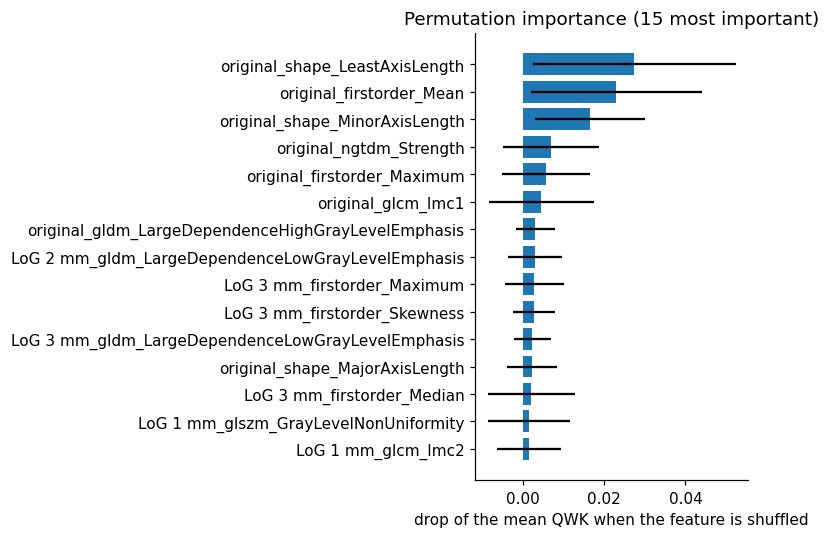

34 of 63 features lower the mean QWK when shuffled


In [23]:
# The 15 most important features, with the standard deviation over folds and repeats
importance = pd.read_csv(MODEL_RESULTS_DIR / f"permutation_importance_{final_tag}.csv", index_col=0)
top = importance.head(15).iloc[::-1]
short_names = [name.replace("log-sigma-", "LoG ").replace("-0-mm-3D", " mm") for name in top.index]
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(short_names, top["importance"], xerr=top["sd"], color="tab:blue")
ax.set(xlabel="drop of the mean QWK when the feature is shuffled", title="Permutation importance (15 most important)")
plt.tight_layout()
plt.show()
print(f"{(importance['importance'] > 0).sum()} of {len(importance)} features lower the mean QWK when shuffled")

In [24]:
# How the predicted probability of a suspicious nodule grows with the diameter, against the observed share
size = pd.cut(nodules["roi_diameter_mm"], [0, 5, 8, 12, 20, 100],
              labels=["under 5 mm", "5 to 8", "8 to 12", "12 to 20", "20 mm or more"])
pd.DataFrame({
    "nodules": size.value_counts(sort=False),
    "observed share of suspicious": pd.Series(is_suspicious).groupby(size, observed=False).mean(),
    "predicted probability": pd.Series(probability).groupby(size, observed=False).mean(),
}).round(2)

,nodules,observed share of suspicious,predicted probability
roi_diameter_mm,,,
under 5 mm,1266,0.03,0.09
5 to 8,1201,0.10,0.19
8 to 12,414,0.43,0.45
12 to 20,264,0.80,0.80
20 mm or more,92,0.78,0.90


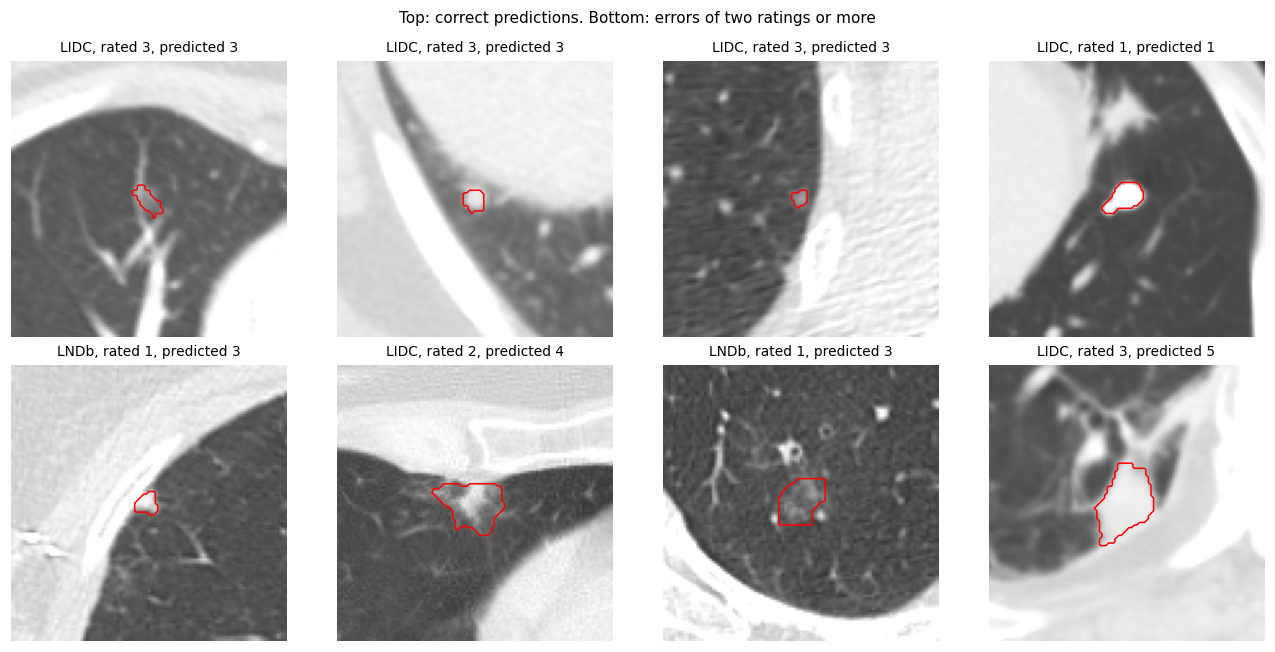

In [25]:
# Central axial slice with the consensus contour: four correct predictions and four errors of two ratings or more
manifest = pd.concat([pd.read_csv(LNDB_MANIFEST_FILE), pd.read_csv(LIDC_MANIFEST_FILE)])
file_of = dict(zip(manifest["patch_id"], manifest["file"]))
error = np.abs(decoded - nodules["rating"].to_numpy())
rng = np.random.default_rng(0)
correct = rng.choice(np.flatnonzero(error == 0), 4, replace=False)
wrong = rng.choice(np.flatnonzero(error >= 2), 4, replace=False)

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for axis, row in zip(axes.ravel(), list(correct) + list(wrong)):
    nodule = nodules.iloc[row]
    patch = np.load(PATCHES_DIR / file_of[nodule["patch_id"]])
    rois = np.load(ROI_DIR / f"{nodule['patch_id']}.npz")
    axis.imshow(patch[CENTRE_INDEX], cmap="gray", vmin=-1350, vmax=150)      # lung window
    axis.contour(rois["consensus"][CENTRE_INDEX], levels=[0.5], colors="red", linewidths=1)
    axis.set_title(f"{nodule['dataset']}, rated {nodule['rating']}, predicted {decoded[row]}", fontsize=9)
    axis.axis("off")
fig.suptitle("Top: correct predictions. Bottom: errors of two ratings or more", fontsize=10)
plt.tight_layout()
plt.show()

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
  The model relies mainly on size and density. The two most important features are the shortest axis of the nodule (least axis length) and its mean density (first order mean), followed by the second shortest axis (minor axis length): shuffling one of them lowers the mean QWK by 0.016 to 0.027. Texture comes next, with smaller effects: the NGTDM strength, the brightest value inside the nodule (first order maximum) and the GLCM informational correlation, which describe how heterogeneous the nodule is. These are the signs that radiologists use: size, solid or ground glass density, and an irregular internal structure. 34 of the 63 features lower the mean QWK when shuffled; many others share their information with correlated features, so their own importance looks small.
  </p>
  <p>
  The predicted probability of a suspicious nodule follows the observed share closely across sizes: 0.09 against 0.03 under 5 mm, 0.19 against 0.10 from 5 to 8 mm, 0.45 against 0.43 from 8 to 12 mm, 0.80 against 0.80 from 12 to 20 mm and 0.90 against 0.78 above 20 mm. The excess for the smallest nodules is the effect of the weights seen in the calibration.
  </p>
  <p>
  The examples of large errors are two small LNDb nodules rated 1 but predicted 3, one against the pleura and one with an irregular, partly ground glass region; a LIDC IDRI nodule rated 2 but predicted 4, irregular and partly solid; and a large solid LIDC IDRI nodule rated 3 but predicted 5. In each case the region shows signs that usually go with malignancy (size, an irregular border or ground glass), and the radiologists probably used information that the patch does not show, such as the history of the patient or earlier scans.
  </p>
</div>

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   Median, mean or mode of the ratings
  </h3>
  <p>
  The label is the median of the ratings by design (notebook 03). To see what that choice changes, the final configuration is trained again, with the same folds and the same inner loop, on the mean and on the mode of the ratings, and every version is evaluated in two ways: against the median label used everywhere in this notebook, and against every single radiologist, which does not depend on any rule. This check does not change any choice. Notebooks 02 and 03 showed that the three rules give the same label to every nodule read by one or two radiologists, so any difference can only come from the nodules read by three or four, almost all in LIDC IDRI.
  </p>
</div>

In [26]:
keys = ["label_median", "label_mean", "label_mode"]
columns = ["mean_qwk", "difference", "difference_low", "difference_high", "mean_auc", "auc_difference",
           "reader_qwk_LNDb", "reader_qwk_LIDC", "reader_auc_LNDb", "reader_auc_LIDC"]
display(summary.loc[keys, columns].round(3))

# QWK in LIDC IDRI by number of readers: against the median label, and against the label each version was trained on
lidc = (nodules["dataset"] == "LIDC").to_numpy()
rows = {}
for rule, key in (("median", final_key), ("mean", f"label_mean_{final_tag}"), ("mode", f"label_mode_{final_tag}")):
    decoded_rule = load_result(key)["decoded"]
    own = nodules["rating"] if rule == "median" else nodules[f"rating_{rule}"]
    for readers in (1, 2, 3, 4):
        part = lidc & (nodules["n_rated"] == readers).to_numpy()
        rows[(rule, readers)] = {
            "nodules": part.sum(),
            "QWK against the median": np.mean([qwk(nodules["rating"][part], d[part]) for d in decoded_rule]),
            "QWK against its own label": np.mean([qwk(own[part], d[part]) for d in decoded_rule]),
        }
pd.DataFrame(rows).T.rename_axis(["trained on", "readers"]).round(3)

,mean_qwk,difference,difference_low,difference_high,mean_auc,auc_difference,reader_qwk_LNDb,reader_qwk_LIDC,reader_auc_LNDb,reader_auc_LIDC
config,,,,,,,,,,
label_median,0.624,NaN,NaN,NaN,0.862,NaN,0.535,0.556,0.834,0.825
label_mean,0.620,-0.005,-0.012,0.004,0.865,0.003,0.544,0.542,0.839,0.824
label_mode,0.623,-0.001,-0.008,0.005,0.861,-0.001,0.530,0.562,0.831,0.824


nodules  QWK against the median  QWK against its own label
trained on readers                                                            
median     1          772.0                   0.392                      0.392
           2          481.0                   0.600                      0.600
           3          482.0                   0.688                      0.688
           4          880.0                   0.800                      0.800
mean       1          772.0                   0.382                      0.382
           2          481.0                   0.578                      0.578
           3          482.0                   0.659                      0.641
           4          880.0                   0.783                      0.769
mode       1          772.0                   0.394                      0.394
           2          481.0                   0.607                      0.607
           3          482.0                   0.688                      0.688
           4          880.0                   0.805                      0.781

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
  The rule that combines the readers changes the model very little. Trained on the mean, the final configuration reaches a mean QWK of 0.620 against the median label, 0.005 below the version trained on the median (from 0.012 lower to 0.004 higher); trained on the mode, it reaches 0.623 (0.001 lower, from 0.008 lower to 0.005 higher). Against every single radiologist, the measure that favours no rule, the three versions are equal: a QWK of 0.535, 0.544 and 0.530 in LNDb and of 0.556, 0.542 and 0.562 in LIDC IDRI for the median, the mean and the mode, and an AUC between 0.824 and 0.839 for all of them.
  </p>
  <p>
  The table by number of readers shows why. With one or two readers the three rules give the same label, and the three versions differ only by the noise of training. With three and four readers the mean gives another label to 249 nodules, and there the version trained on the mean agrees less with its own label (0.641 and 0.769) than the version trained on the median with its own (0.688 and 0.800): a mean pulled towards 3 by one dissenting reader is harder to learn than the rating that most readers share. The mode behaves like the median, as expected, since it differs from it only for 78 nodules read by four radiologists.
  </p>
  <p>
  The choice of the median is therefore safe: no rule changes how well the model agrees with the radiologists, and the median gives the label that is easiest to learn where the readers disagree. The table also shows how much the agreement grows with the number of readers, from 0.39 with one reader to 0.80 with four. A label built from more readers is less noisy and the model agrees with it far better, so a large part of the remaining error is noise in the label rather than error of the model.
  </p>
</div>

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   Conclusions and limits
  </h3>
  <p>
  The final configuration is an <strong>ordinal logistic regression on 63 robust PyRadiomics features of the original and LoG images, with the rare ratings weighted up, one model for both datasets, trained on the median rating of the radiologists, which predicts the most probable rating and calls a nodule suspicious when its probability of a rating of 4 or 5 passes a threshold chosen in the inner folds</strong>. On new splits it reaches a mean QWK of 0.621 (from 0.576 to 0.661) on the 1 to 5 scale, 0.557 in LNDb and 0.686 in LIDC IDRI, and a mean AUC of 0.861 (from 0.833 to 0.886) on the binary scale. It agrees with every single radiologist (QWK 0.533 in LNDb and 0.555 in LIDC IDRI) as well as one radiologist agrees with the others (0.527 and 0.528). The wavelet features, a dataset indicator, ComBat, one model per dataset, the random forest, gradient boosting, the SVM, a model trained directly on the binary label and the elastic net did not beat it beyond the noise. Trained on LIDC IDRI only, it keeps its performance in LNDb; trained on LNDb only, it loses 0.040 in LIDC IDRI.
  </p>
  <p>
  Limits:
  </p>
  <ul style="padding-left: 20px; margin-bottom: 20px;">
    <li style="margin-bottom: 8px;">The label is a subjective rating of malignancy by radiologists, not a diagnosis confirmed by biopsy or follow up, so the model learns how radiologists rate nodules, not whether a nodule is cancer.</li>
    <li style="margin-bottom: 8px;">For the binary answer, size explains almost everything: the diameter alone reaches the same AUC as the full model. The other features mainly help to place a nodule on the 1 to 5 scale.</li>
    <li style="margin-bottom: 8px;">The threshold of the binary answer depends on the hospital: one threshold for both datasets gives a sensitivity of 0.50 in LNDb against 0.82 in LIDC IDRI, and a threshold chosen in one dataset is wrong in the other. A hospital that adopts the model must set its own threshold, and a threshold with a higher sensitivity would be a clinical choice, stating that a missed suspicious nodule costs more than a false alarm.</li>
    <li style="margin-bottom: 8px;">The weights make the probabilities too high, so they need a recalibration before they can be read as risks.</li>
    <li style="margin-bottom: 8px;">All results come from the training data of the two datasets. Training on one and validating on the other is the closest we get to a new hospital, but the two differ in scanners and in readers at the same time.</li>
    <li style="margin-bottom: 8px;">Many options were compared across the stages. The confirmation on new seeds shows little optimism (about 0.003), but the margin of the final choice over the unweighted model is small (0.016, from 0.002 to 0.032).</li>
    <li style="margin-bottom: 8px;">Gradient boosting and the SVM are insensitive to their hyperparameters on these data, so the values chosen for them are the simplest of many equally good ones rather than a sharp optimum.</li>
    <li style="margin-bottom: 8px;">The features describe only the region drawn by the radiologists. Context outside the nodule, which radiologists also look at, is not used.</li>
  </ul>
</div>